# Creating A Fraud Detection System Using XG Boost Algorithms
## Steps
* 1. DataSet Load
* 2. EDA
* 3. Data quality and leakage analysis
* 4. Feature Engineering
* 5. Normalization
* 6. Train Test Split
* 7. Training Model
* 8. Performance Evaluation


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## DataSets Load

In [2]:
data_path = "data/raw/fraud_datasets/"

# Load datasets into separate DataFrames
df_ieee = pd.read_parquet(
    data_path + "ieee_cis_card_payments_real.parquet"
)

df_baf_bank = pd.read_parquet(
    data_path + "baf_bank_account_opening_synthetic.parquet"
)

df_mobile = pd.read_parquet(
    data_path + "momtsim_mobile_money_synthetic.parquet"
)

df_paysim = pd.read_parquet(
    data_path + "paysim_mobile_money_synthetic.parquet"
)

df_xente = pd.read_parquet(
    data_path + "xente_mobile_money_uganda_real.parquet"
)

# Display dataset shapes
print("IEEE Dataset Shape:", df_ieee.shape)
print("BAF Bank Dataset Shape:", df_baf_bank.shape)
print("Mobile Dataset Shape:", df_mobile.shape)
print("PaySim Dataset Shape:", df_paysim.shape)
print("Xente Dataset Shape:", df_xente.shape)

IEEE Dataset Shape: (590540, 438)
BAF Bank Dataset Shape: (1000000, 36)
Mobile Dataset Shape: (4225958, 9)
PaySim Dataset Shape: (6362620, 9)
Xente Dataset Shape: (95662, 19)


# EDA

## Organize all five datasets

In [3]:
datasets = {
    "IEEE-CIS": df_ieee,
    "BAF Bank": df_baf_bank,
    "MoMTSim": df_mobile,
    "PaySim": df_paysim,
    "Xente": df_xente
}

In [4]:
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## Dataset overview

In [5]:
overviews = []
for name, df in datasets.items():
    overviews.append({
        "Dataset" : name,
        "Rows" : df.shape[0],
        "Columns" : df.shape[1],
        "Memory Usage (MB)" : df.memory_usage(deep=True).sum() / (1024 ** 2),
        "Duplicate values" : df.duplicated().sum(),
        "Missing values" : df.isnull().sum().sum()
    })


overview_df = pd.DataFrame(overviews)
display(overview_df)

,Dataset,Rows,Columns,Memory Usage (MB),Duplicate values,Missing values
0,IEEE-CIS,590540,438,1987.084618,0,116704153
1,BAF Bank,1000000,36,267.835718,0,2000000
2,MoMTSim,4225958,9,331.204257,78,0
3,PaySim,6362620,9,445.299651,0,0
4,Xente,95662,19,23.237107,0,0


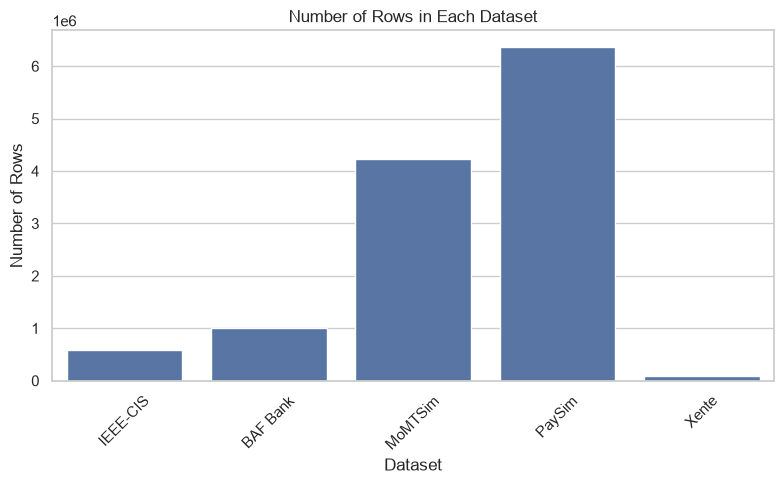

In [6]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=overview_df,
    x = "Dataset",
    y = "Rows"
)

plt.title("Number of Rows in Each Dataset")
plt.xlabel("Dataset")
plt.ylabel("Number of Rows")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Data types analysis

In [7]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(f"DATASET: {name}")
    print("=" * 60)

    print("Numerical Features:", len(df.select_dtypes(include=np.number).columns))
    print("Categorical Features:", len(df.select_dtypes(include=["object", "category"]).columns))
    print("Datetime Features:", len(df.select_dtypes(include=["datetime"]).columns))

    print("\nData Types:")
    print(df.dtypes.value_counts())

    print("\nColumn Names:")
    print(df.columns.tolist())



DATASET: IEEE-CIS
Numerical Features: 403
Categorical Features: 33
Datetime Features: 0

Data Types:
float64     399
str          31
int64         3
category      1
category      1
int8          1
string        1
boolean       1
Name: count, dtype: int64

Column Names:
['dataset', 'split', 'ts', 'label', 'user_id', 'seen_user', 'TransactionID', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', '

## Missing values analysis

In [8]:
for name, df in datasets.items():
    missing = pd.DataFrame({
        "Missing Counts" : df.isnull().sum(),
        "Missing Percentage" : (df.isnull().sum() / len(df)) * 100
    })

    missing = missing[missing["Missing Counts"] > 0].sort_values(by="Missing Percentage", ascending=False)

    print(f"\{name} Dataset - Missing Values Analysis")
    display(missing.head(30))

\IEEE-CIS Dataset - Missing Values Analysis


,Missing Counts,Missing Percentage
user_id,590540,100.000000
seen_user,590540,100.000000
id_24,585793,99.196159
id_25,585408,99.130965
id_07,585385,99.127070
id_08,585385,99.127070
id_21,585381,99.126393
id_26,585377,99.125715
id_27,585371,99.124699
id_23,585371,99.124699


\BAF Bank Dataset - Missing Values Analysis


,Missing Counts,Missing Percentage
user_id,1000000,100.0
seen_user,1000000,100.0


\MoMTSim Dataset - Missing Values Analysis


,Missing Counts,Missing Percentage


\PaySim Dataset - Missing Values Analysis


,Missing Counts,Missing Percentage


\Xente Dataset - Missing Values Analysis


,Missing Counts,Missing Percentage


### Visualize missing values

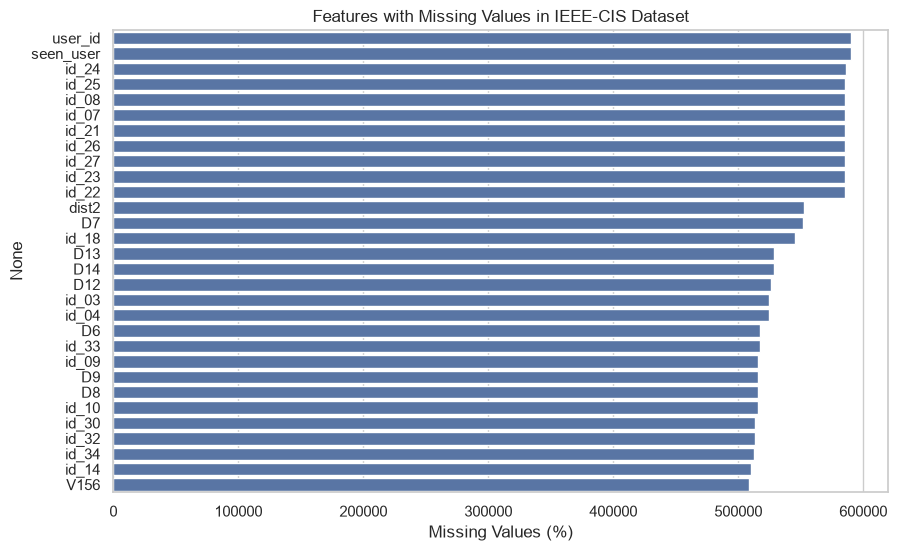

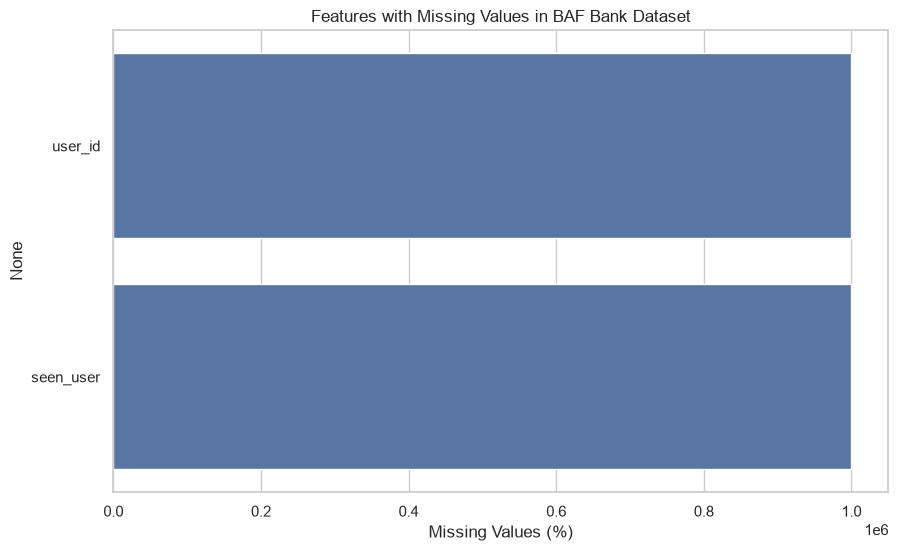


MoMTSim Dataset - No Missing Values

PaySim Dataset - No Missing Values

Xente Dataset - No Missing Values


In [9]:
for name, df in datasets.items():
    missing = (
        df.isnull().sum()
    ).sort_values(ascending=False)

    missing = missing[missing > 0].head(30)

    if len(missing) == 0:
        print(f"\n{name} Dataset - No Missing Values")
        continue

    plt.figure(figsize=(10, 6))
    sns.barplot(
        x = missing.values,
        y = missing.index
    )

    plt.title(f"Features with Missing Values in {name} Dataset")
    plt.xlabel("Missing Values (%)")
    plt.show()

## Duplicate records analysis

In [10]:
duplicate_results = []
for name, df in datasets.items():
    duplicate_count = df.duplicated().sum()
    duplicate_percentage = (duplicate_count / len(df)) * 100

    duplicate_results.append({
        "Dataset" : name,
        "Duplicate Counts" : duplicate_count,
        "Duplicate Percentage" : duplicate_percentage
    })


duplicate_df = pd.DataFrame(duplicate_results)
display(duplicate_df)

,Dataset,Duplicate Counts,Duplicate Percentage
0,IEEE-CIS,0,0.000000
1,BAF Bank,0,0.000000
2,MoMTSim,78,0.001846
3,PaySim,0,0.000000
4,Xente,0,0.000000


### Numerical feature analysis

In [11]:
for name, df in datasets.items():

    numerical = df.select_dtypes(include=np.number)

    report = pd.DataFrame({
        "Skewness": numerical.skew(),
        "Kurtosis": numerical.kurtosis(),
        "Unique Values": numerical.nunique(),
        "Missing Percentage": (
            numerical.isnull().mean() * 100
        )
    })

    print(f"\n{name}")
    display(report.sort_values("Skewness", ascending=False))


IEEE-CIS


,Skewness,Kurtosis,Unique Values,Missing Percentage
V305,384.226170,147628.249982,2,0.002032
V311,323.831374,156542.416947,3098,0.002032
V129,240.274253,102763.136782,1968,0.053172
V309,224.875268,94325.712591,4236,0.002032
V206,207.881617,54107.101724,1780,76.355370
...,...,...,...,...
V41,-36.956021,1363.753933,2,28.612626
V14,-44.708269,1996.837039,2,12.881939
V107,-48.754036,2374.964098,2,0.053172
V65,-54.450914,2962.913595,2,13.055170



BAF Bank


,Skewness,Kurtosis,Unique Values,Missing Percentage
label,9.363838,85.681638,2,0.0
days_since_request,9.278955,106.569214,989330,0.0
foreign_request,6.053306,34.642587,2,0.0
prev_address_months_count,4.063888,20.031089,374,0.0
session_length_in_minutes,3.304575,14.961305,994887,0.0
bank_branch_count_8w,2.747161,6.502921,2326,0.0
intended_balcon_amount,2.507173,6.846671,994971,0.0
device_distinct_emails_8w,2.430764,30.907411,4,0.0
zip_count_4w,1.456657,2.139983,6306,0.0
current_address_months_count,1.386998,1.356865,423,0.0



MoMTSim


,Skewness,Kurtosis,Unique Values,Missing Percentage
amount,113.471428,15963.133634,603069,0.0
ts,-0.032860,-1.206533,193,0.0
label,-0.113900,-1.987028,2,0.0



PaySim


,Skewness,Kurtosis,Unique Values,Missing Percentage
amount,30.993949,1797.956705,5316900,0.0
label,27.779538,769.702982,2,0.0
ts,0.375177,0.329071,743,0.0



Xente


,Skewness,Kurtosis,Unique Values,Missing Percentage
Value,51.291086,3378.069274,1517,0.0
Amount,51.098490,3363.127739,1676,0.0
label,22.196295,490.685762,2,0.0
PricingStrategy,1.659057,2.087534,4,0.0
CountryCode,NaN,NaN,1,0.0


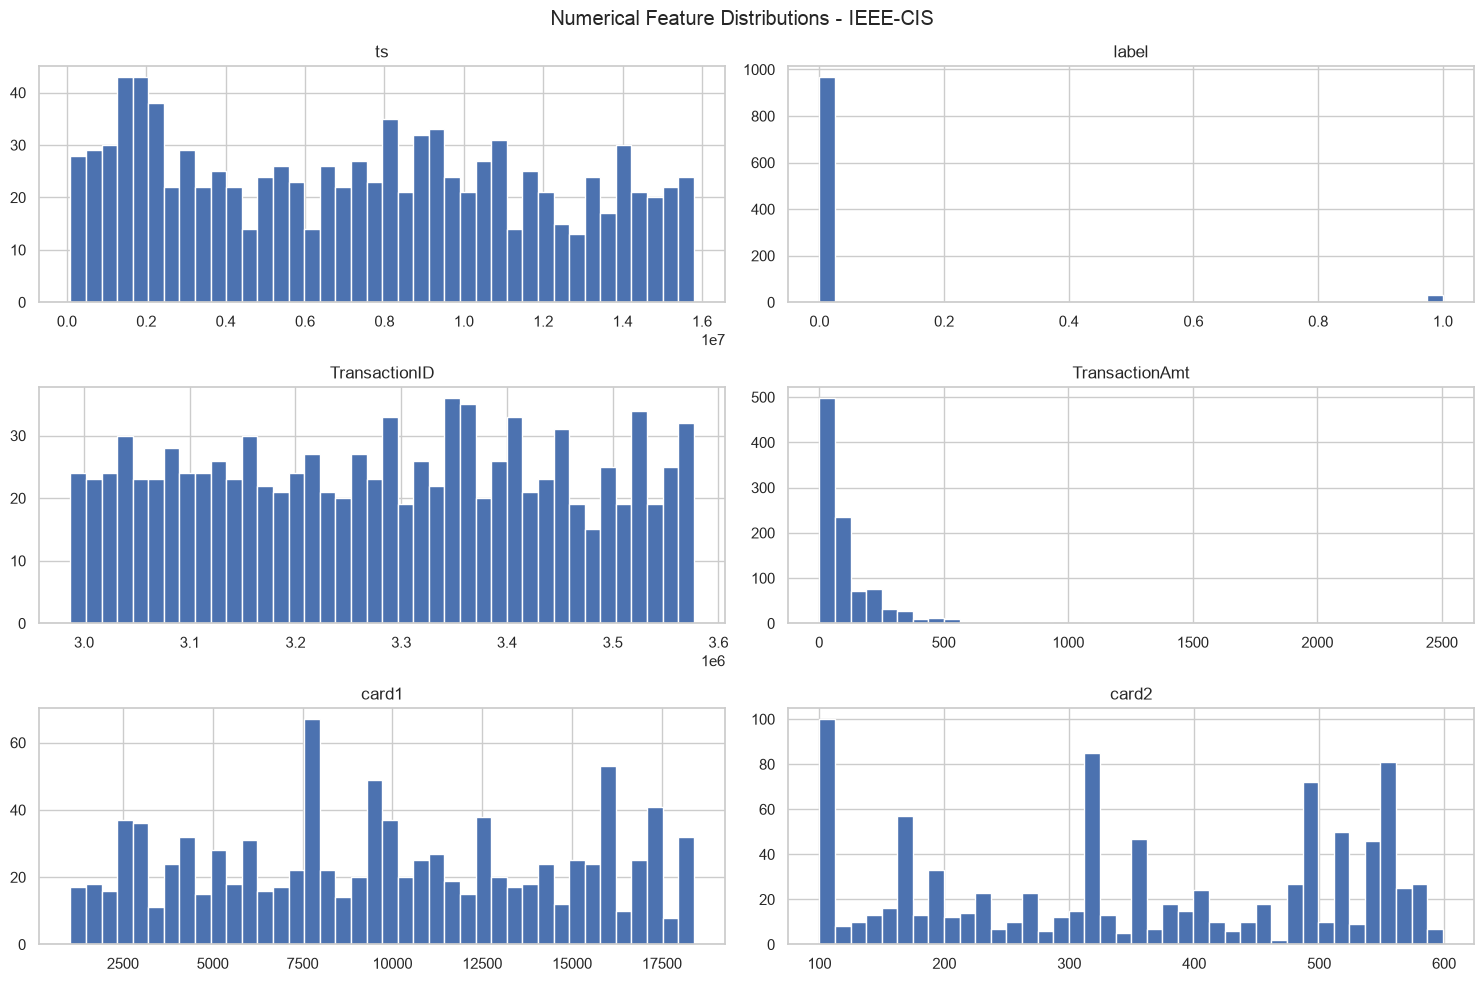

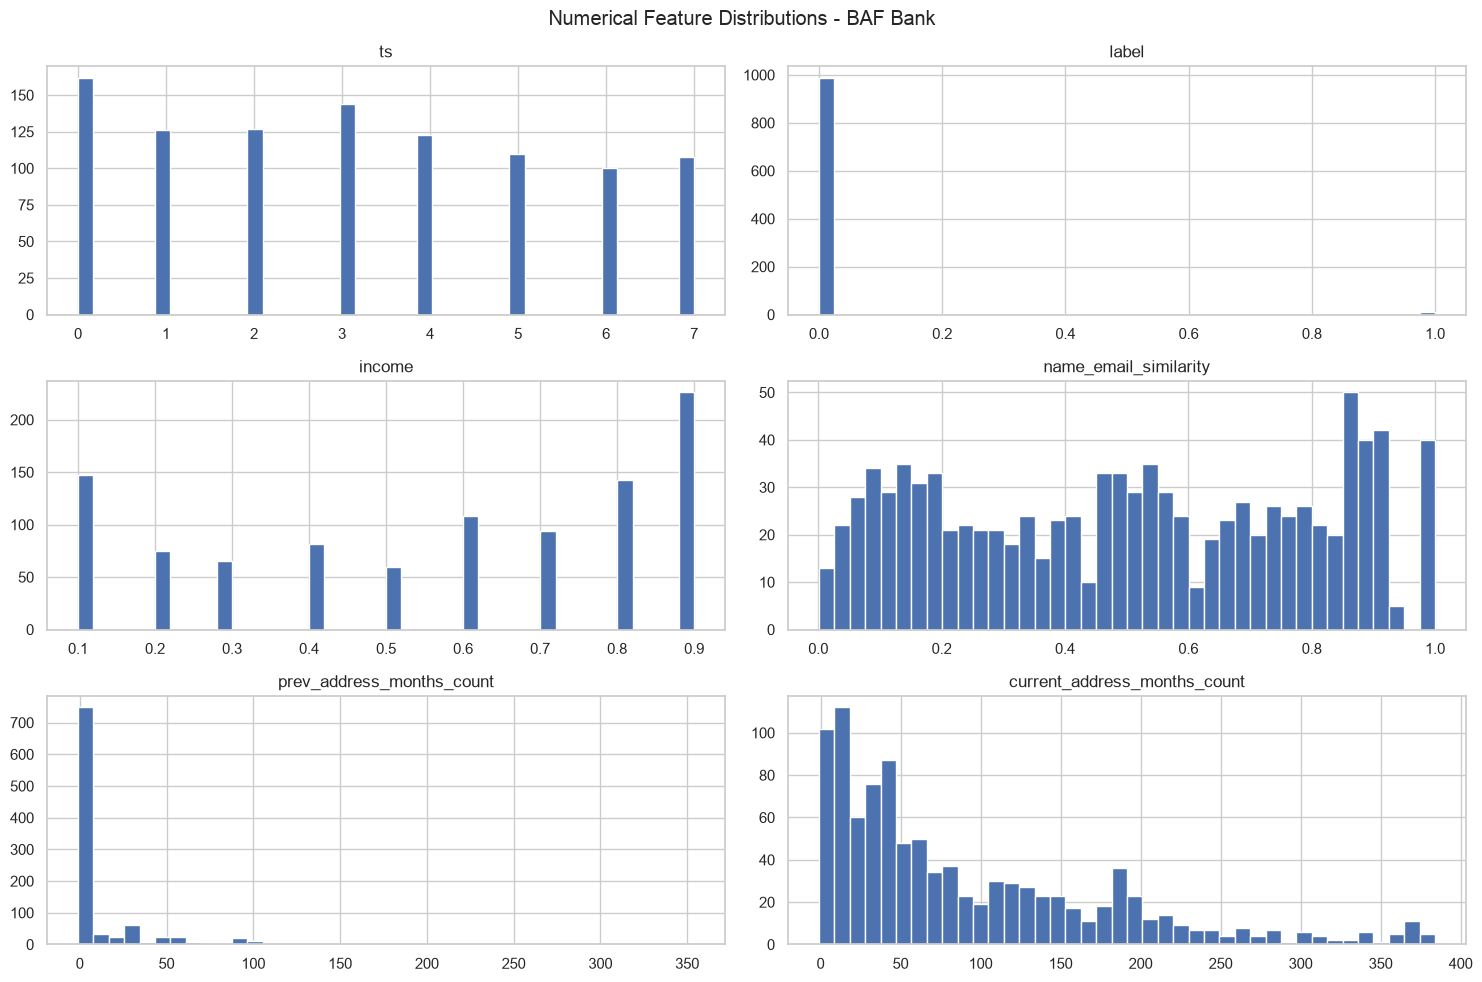

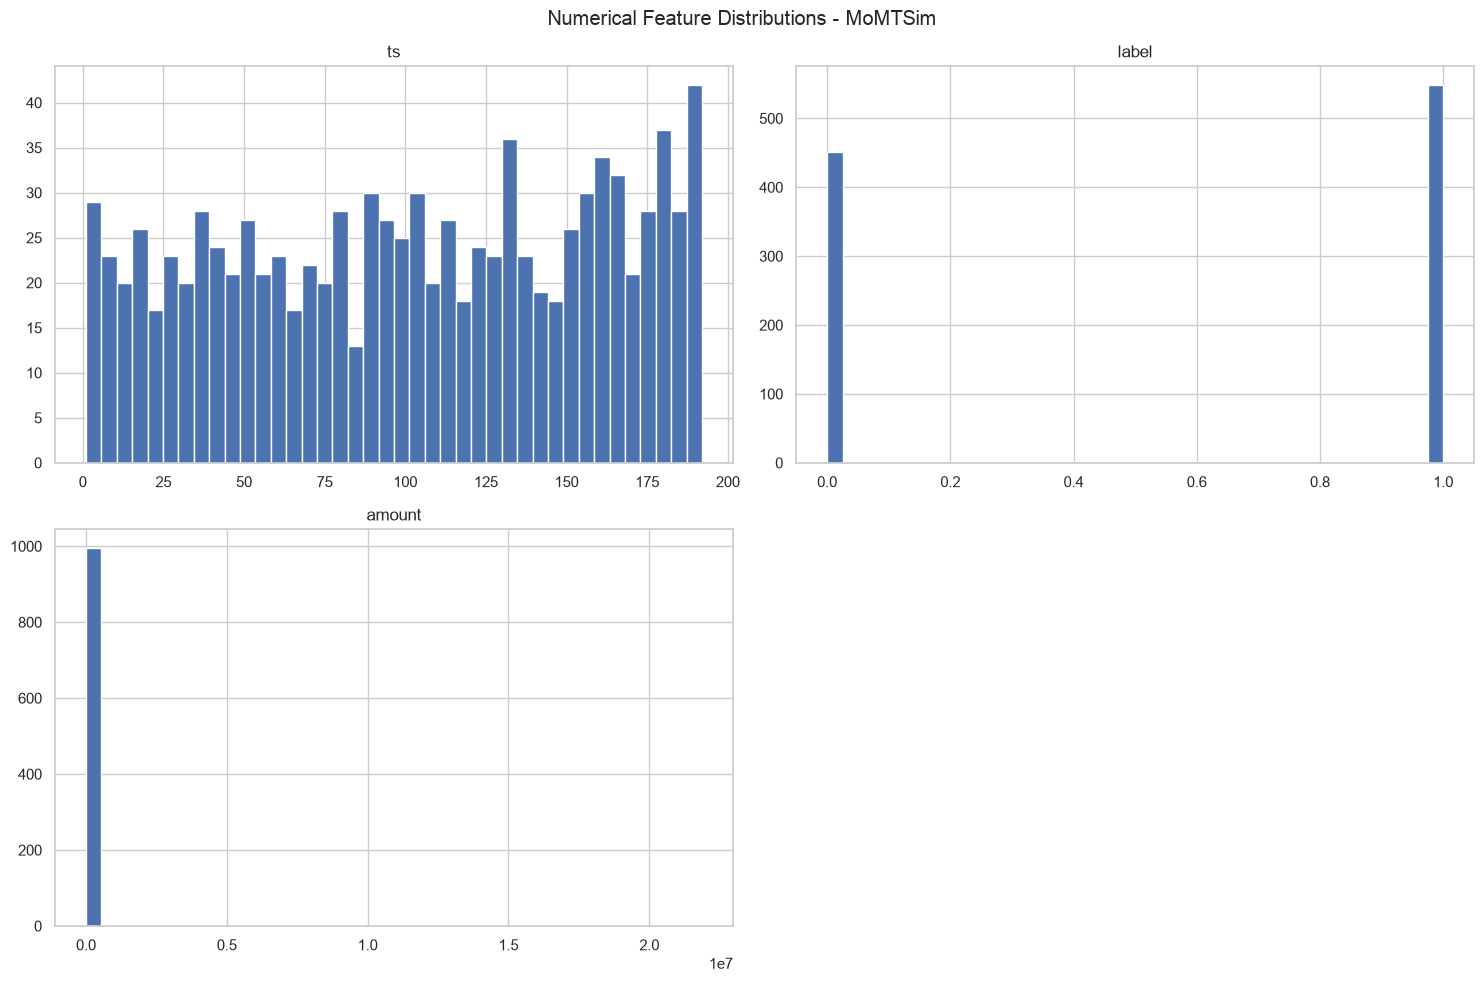

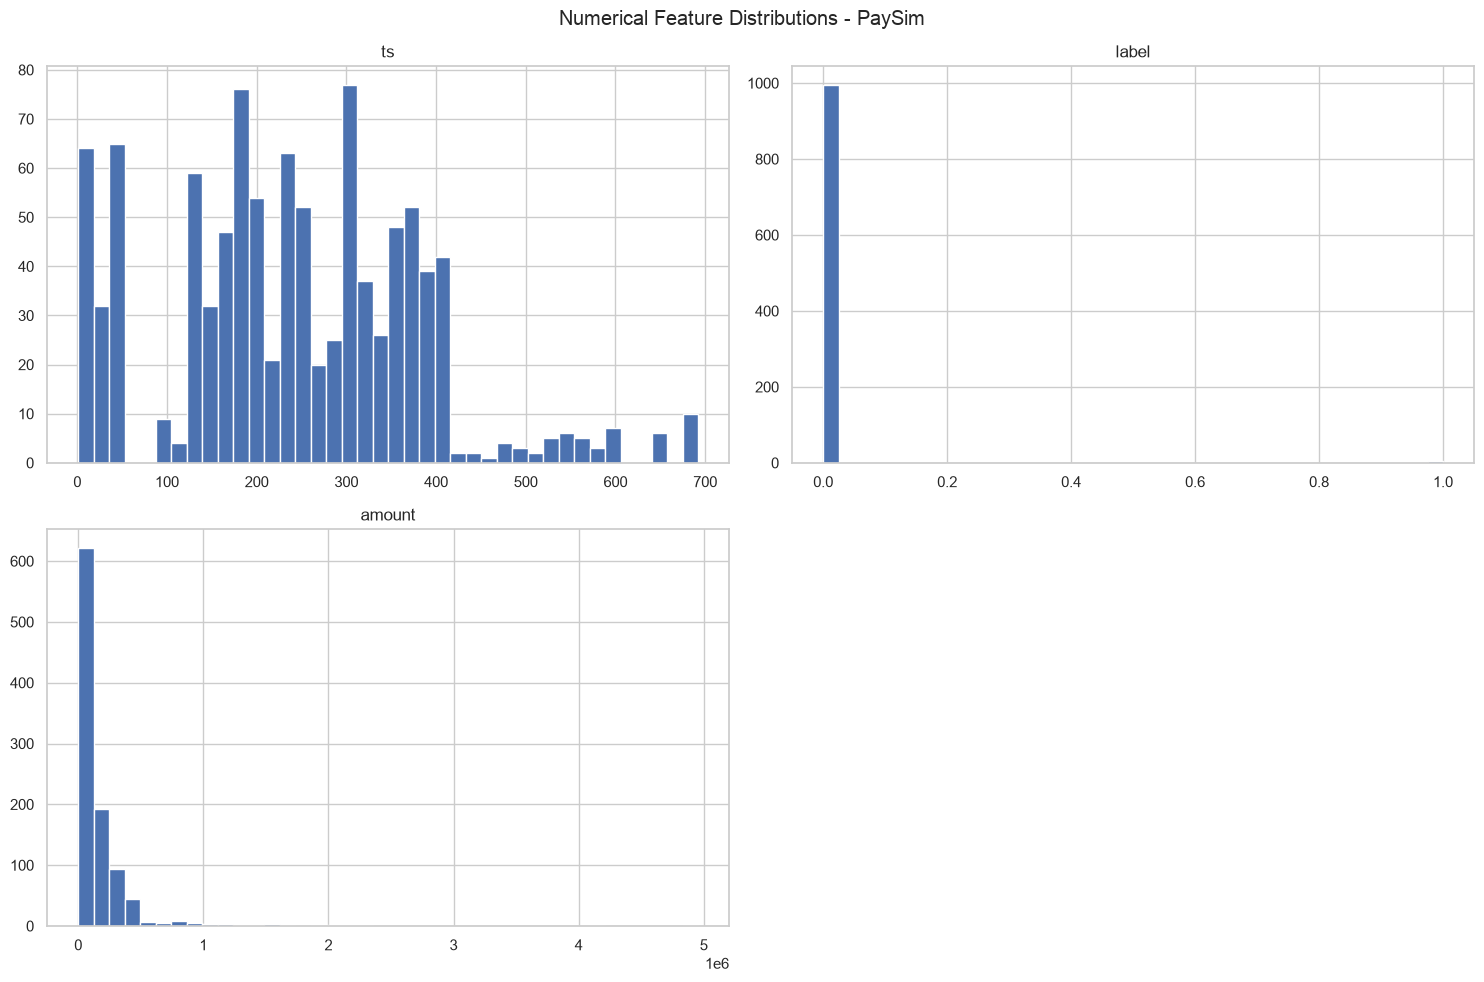

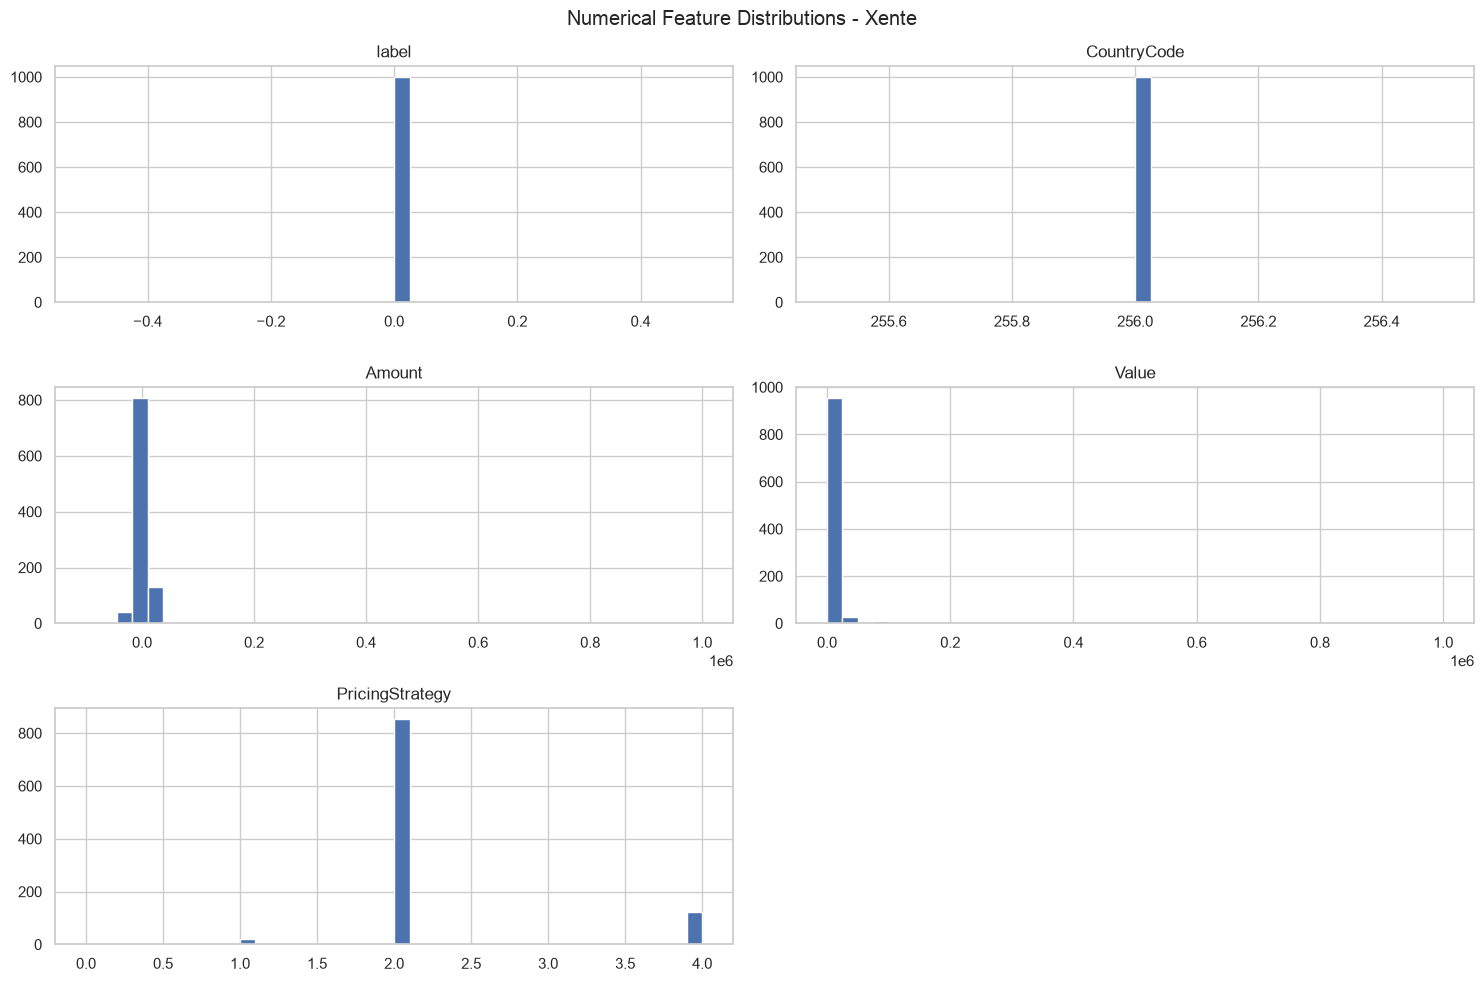

In [12]:
for name, df in datasets.items():
    neumerical_columns = df.select_dtypes(
        include = np.number
    ).columns.tolist()

    neumerical_columns = neumerical_columns[ : 6]

    if not neumerical_columns:
        continue

    df_samples = df[neumerical_columns].sample(
        min(1000, len(df)),
        random_state=42
    )

    df_samples.hist(
        bins=40,
        figsize=(15, 10),
    )

    plt.suptitle(f"Numerical Feature Distributions - {name}")
    plt.tight_layout()
    plt.show()

## Categorical feature analysis

In [13]:
for name, df in datasets.items():
    categorical_columns = df.select_dtypes(
        include = ["object", "category", "bool"]
    ).columns

    print(f"\n{name} Dataset - Categorical Features Analysis")
    print(f"Number of categorical features: {len(categorical_columns)}")

    for col in categorical_columns[ : 10]:
        print(f"\nFeatures: {col}")

        display(df[col].value_counts(dropna=False).head(10))


IEEE-CIS Dataset - Categorical Features Analysis
Number of categorical features: 34

Features: dataset


dataset
ieee    590540
Name: count, dtype: int64


Features: split


split
train         413378
validation     88581
test           88581
Name: count, dtype: int64


Features: seen_user


seen_user
<NA>    590540
Name: count, dtype: Int64

... (66 outputs left out)


Features: ProviderId


ProviderId
ProviderId_4    38189
ProviderId_6    34186
ProviderId_5    14542
ProviderId_1     5643
ProviderId_3     3084
ProviderId_2       18
Name: count, dtype: int64


Features: ProductId


ProductId
ProductId_6     32635
ProductId_3     24344
ProductId_10    15384
ProductId_15    11964
ProductId_1      2885
ProductId_4      2403
ProductId_21     1512
ProductId_11     1377
ProductId_19      965
ProductId_14      789
Name: count, dtype: int64

## Fraud distribution analysis

In [14]:
for  name, df in datasets.items():
    print(f"\n{name}")
    print("=" * 60)

    candidate = [
        col for col in df.columns
        if any(
            word in col.lower()
            for word in ["fraud", "isfraud", "label", "target", "class"]
        )
    ]

    print("Possible Target Columns:", candidate)


IEEE-CIS
Possible Target Columns: ['label']

BAF Bank
Possible Target Columns: ['label', 'device_fraud_count']

MoMTSim
Possible Target Columns: ['label']

PaySim
Possible Target Columns: ['label']

Xente
Possible Target Columns: ['label']


In [15]:
target_columns = {
    "IEEE-CIS": "label",
    "BAF Bank": "label",
    "MoMTSim": "label",
    "PaySim": "label",
    "Xente": "label"
}


IEEE-CIS - Fraud Distribution


label
0    569877
1     20663
Name: count, dtype: int64

label
0    96.501
1     3.499
Name: proportion, dtype: float64

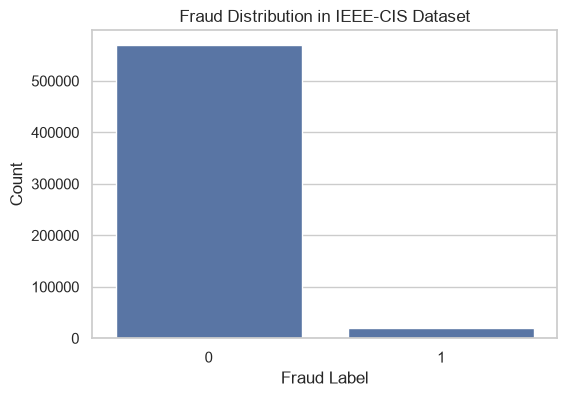


BAF Bank - Fraud Distribution


label
0    988971
1     11029
Name: count, dtype: int64

label
0    98.897
1     1.103
Name: proportion, dtype: float64

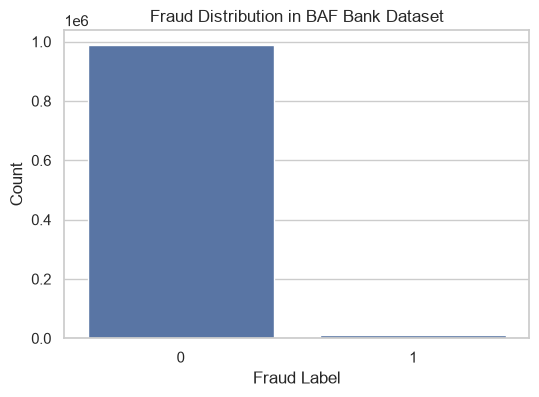


MoMTSim - Fraud Distribution


label
1    2233118
0    1992840
Name: count, dtype: int64

label
1    52.843
0    47.157
Name: proportion, dtype: float64

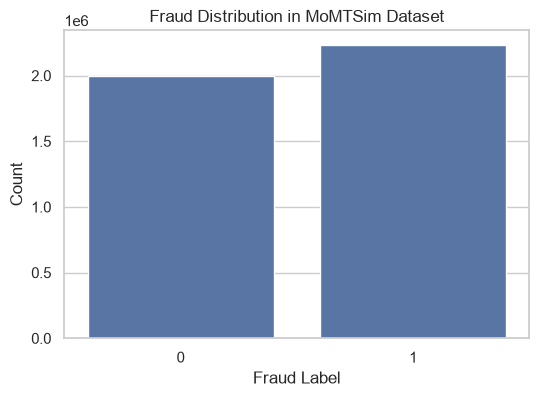


PaySim - Fraud Distribution


label
0    6354407
1       8213
Name: count, dtype: int64

label
0    99.871
1     0.129
Name: proportion, dtype: float64

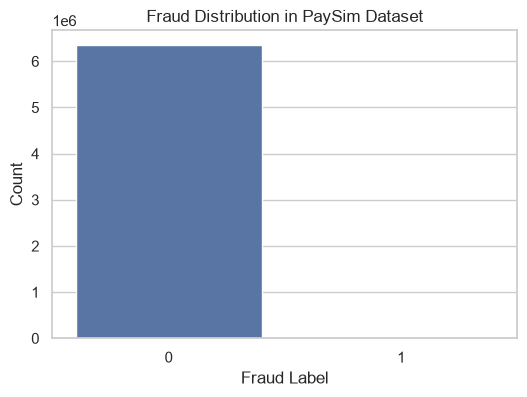


Xente - Fraud Distribution


label
0    95469
1      193
Name: count, dtype: int64

label
0    99.798
1     0.202
Name: proportion, dtype: float64

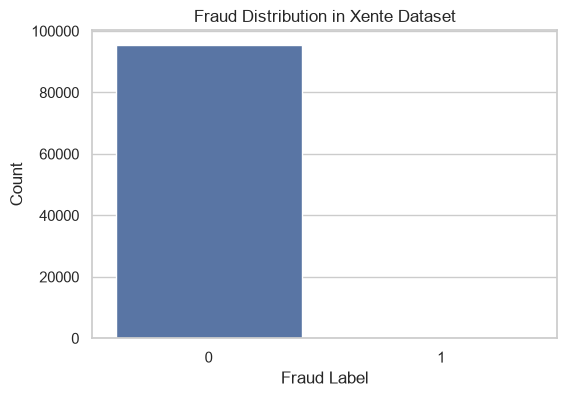

In [16]:
for name, df in  datasets.items():
    target = target_columns[name]

    if target is None:
        print(f"\n{name} Dataset - No target column identified.")
        continue

    print(f"\n{name} - Fraud Distribution")
    display(df[target].value_counts(dropna=False))

    display(
       df[target].value_counts(
            normalize=True,
            dropna=False
       ).mul(100).round(3)
    )

    plt.figure(figsize=(6, 4))

    sns.countplot(
        data=df,
        x=target
    )

    plt.title(f"Fraud Distribution in {name} Dataset")
    plt.xlabel("Fraud Label")
    plt.ylabel("Count")
    plt.show()

## Correlation analysis

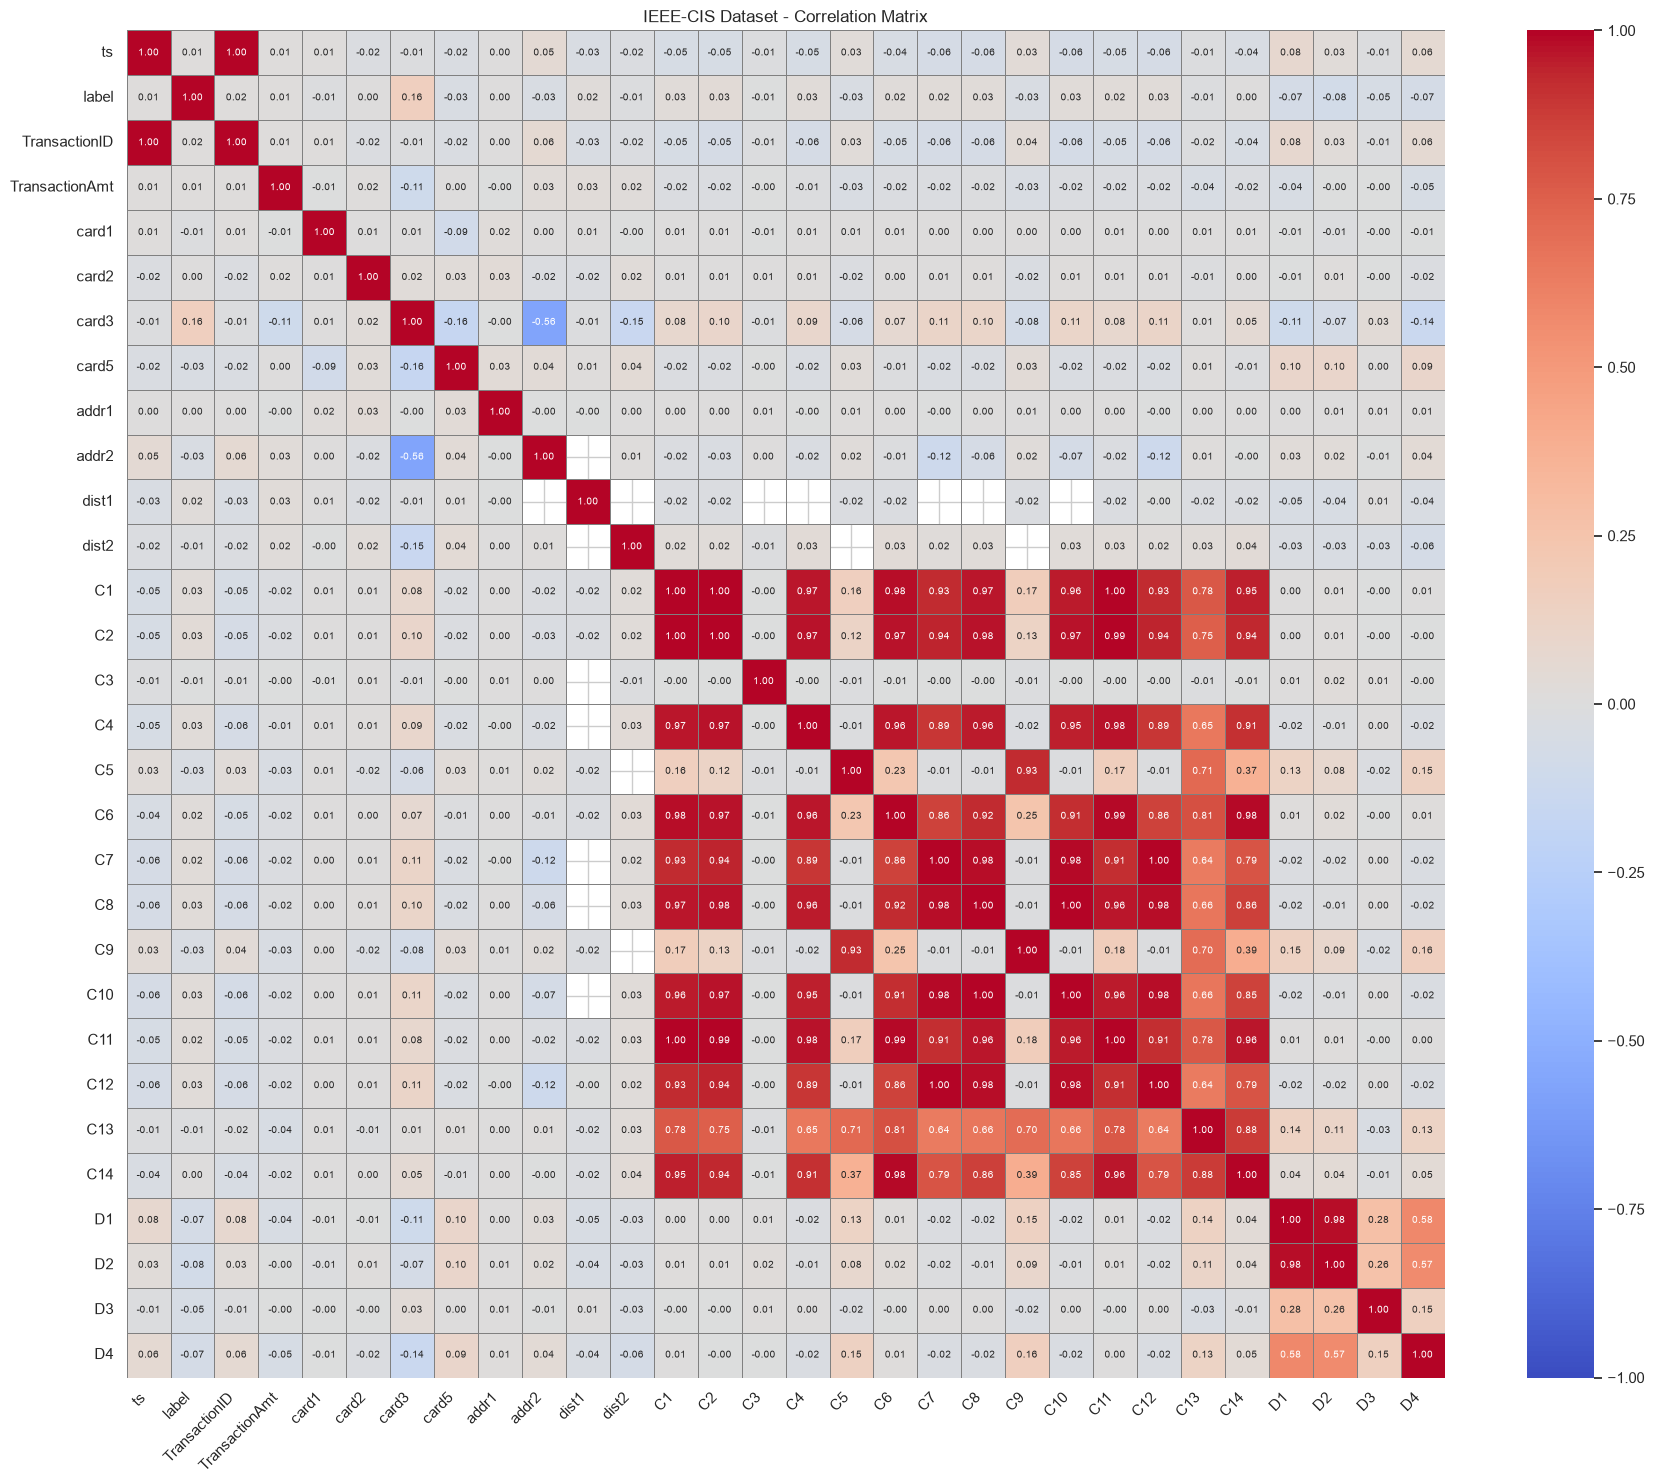

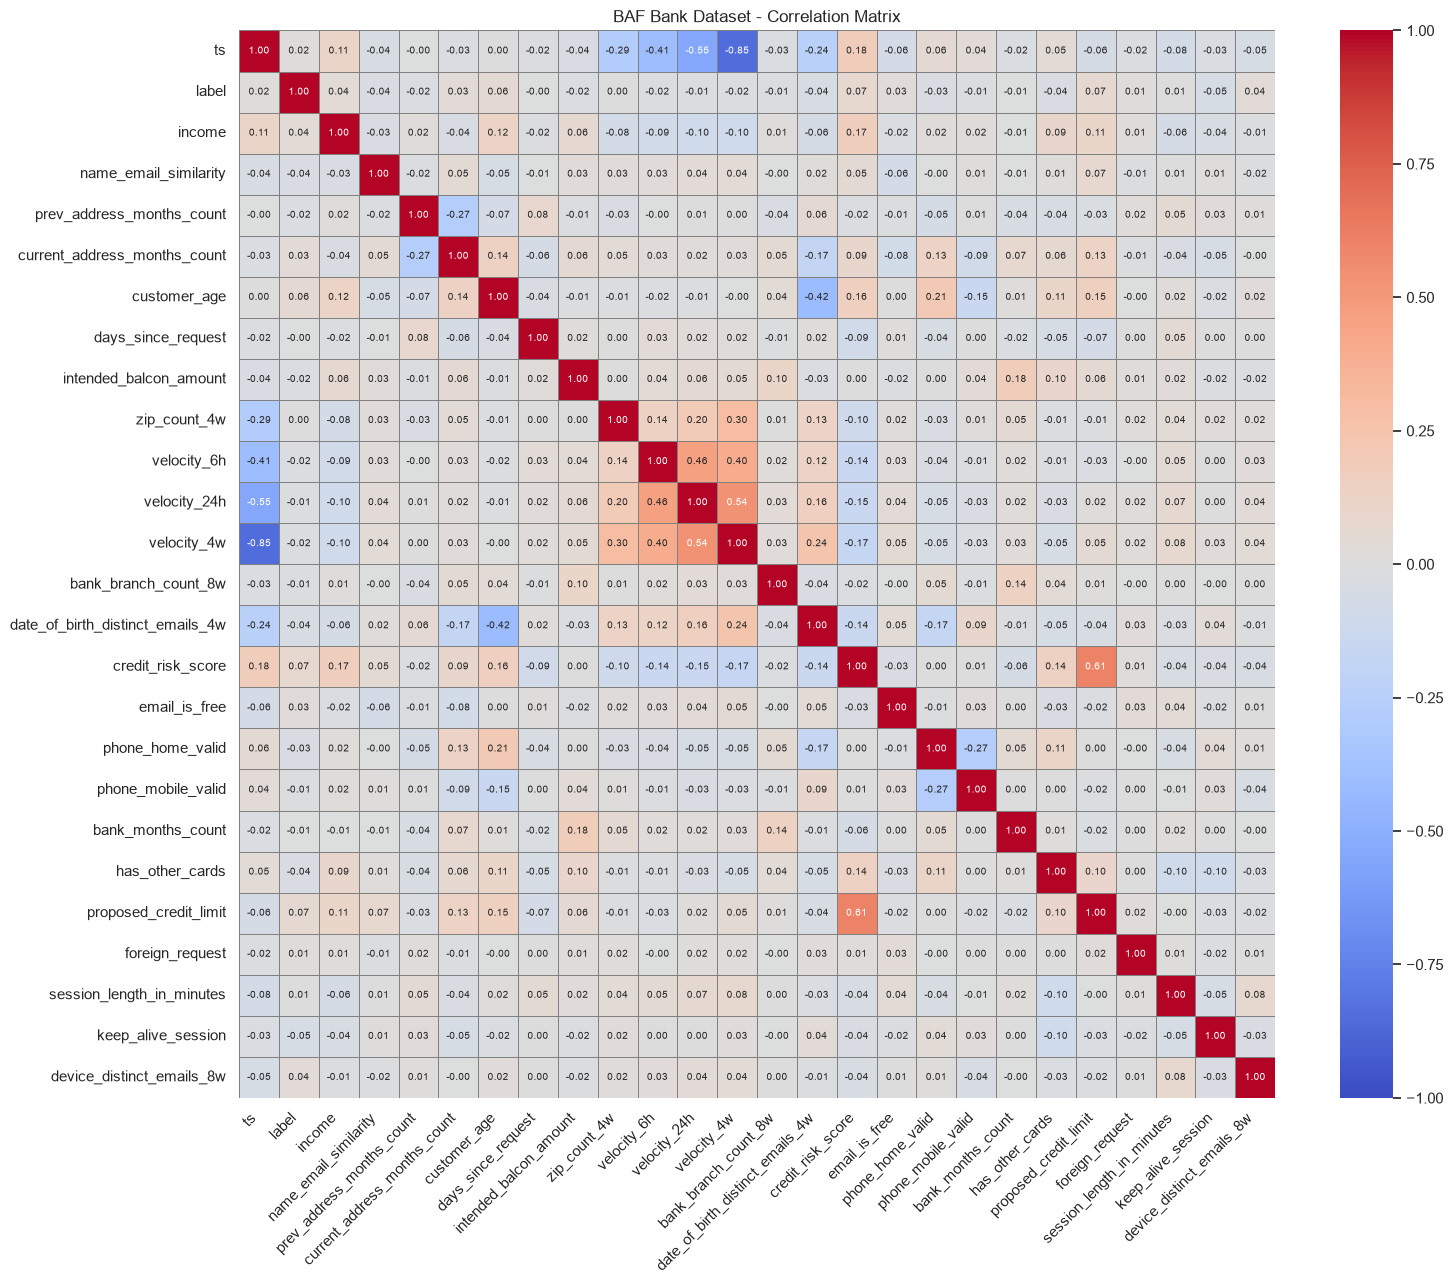

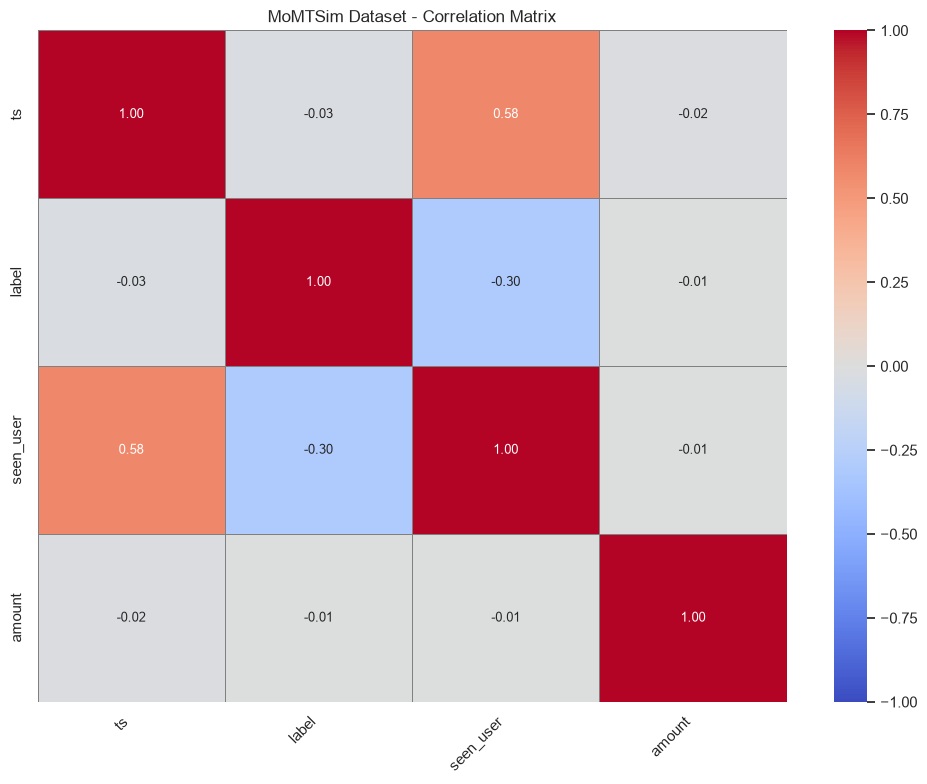

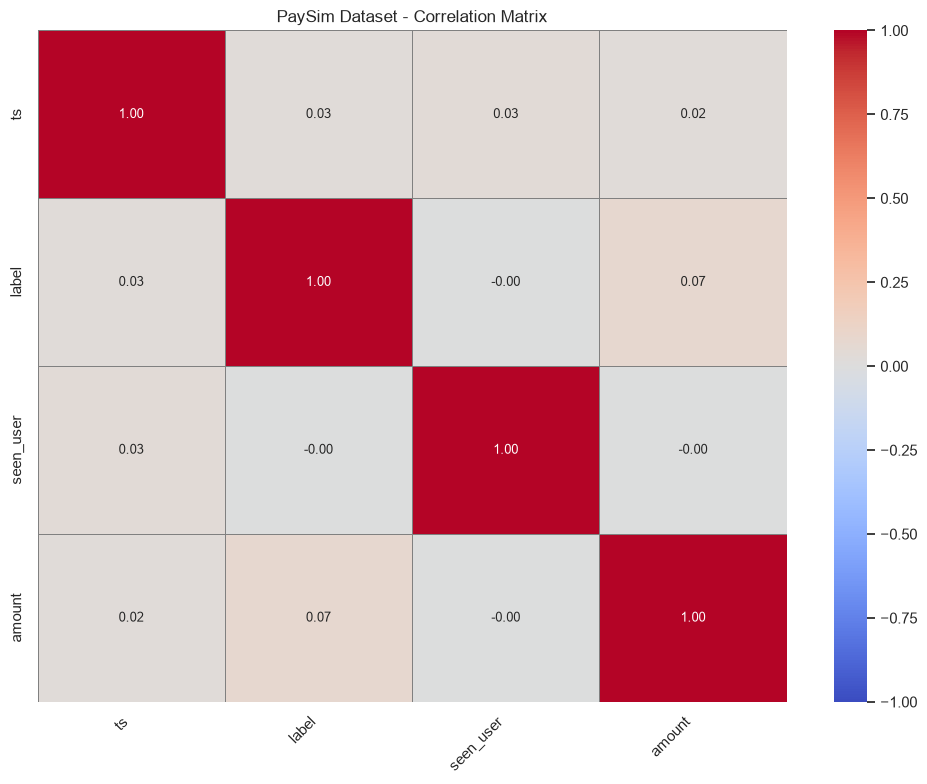

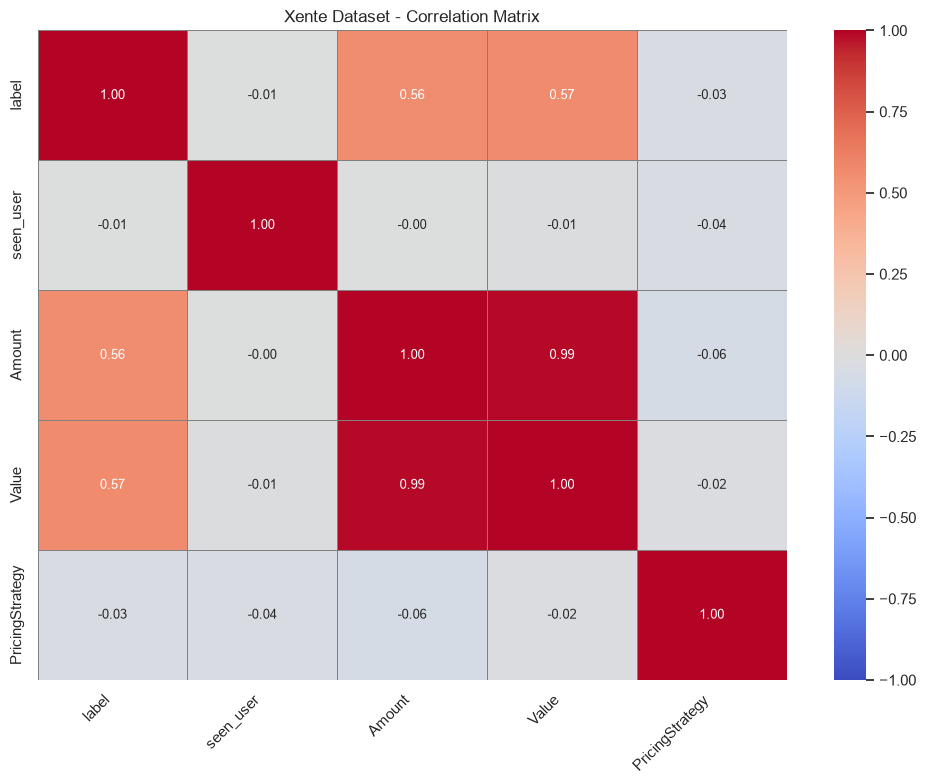

In [18]:
for name, df in datasets.items():
    numerical_df = df.select_dtypes(include=[np.number, "bool"])
    numerical_df = numerical_df.loc[ : , numerical_df.nunique(dropna=False) > 1]

    if numerical_df.shape[1] < 2:
        print(f"\n{name} Dataset - Not enough numerical features for correlation analysis.")
        continue

    if numerical_df.shape[1] > 30:
        numerical_df = numerical_df.iloc[ : , : 30]


    if len(numerical_df) > 200_000:
        numerical_df = numerical_df.sample(200_000, random_state=42)

    correlation = numerical_df.astype(float).corr()

    n = correlation.shape[0]
    plt.figure(figsize=(max(10, n * 0.6), max(8, n * 0.5)))
    sns.heatmap(
        correlation,
        cmap="coolwarm",
        center=0,
        vmin=-1,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7 if n > 15 else 9},
        linewidths=0.5,
        linecolor="gray",
    )

    plt.title(f"{name} Dataset - Correlation Matrix")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## Outlier analysis

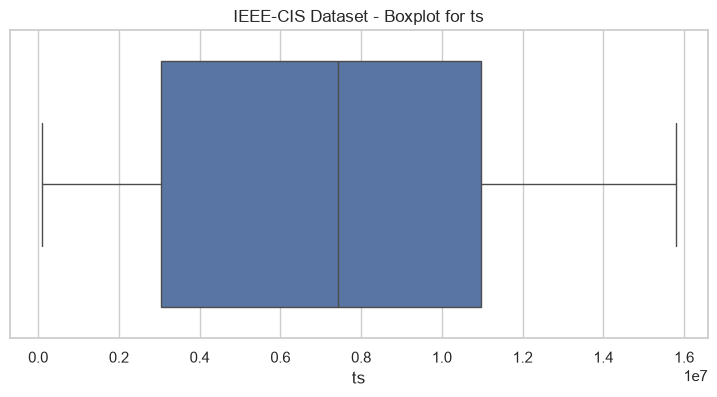

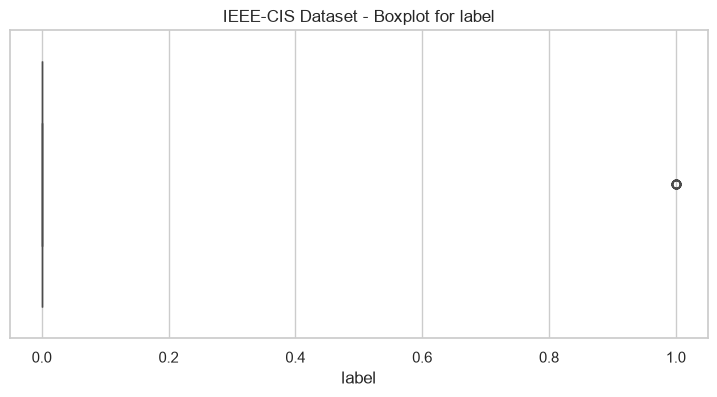

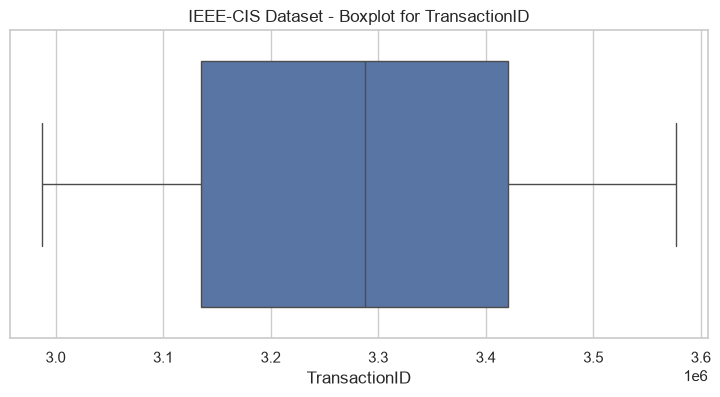

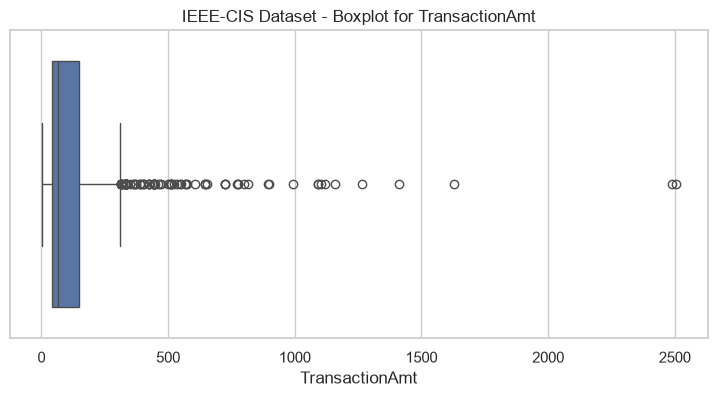

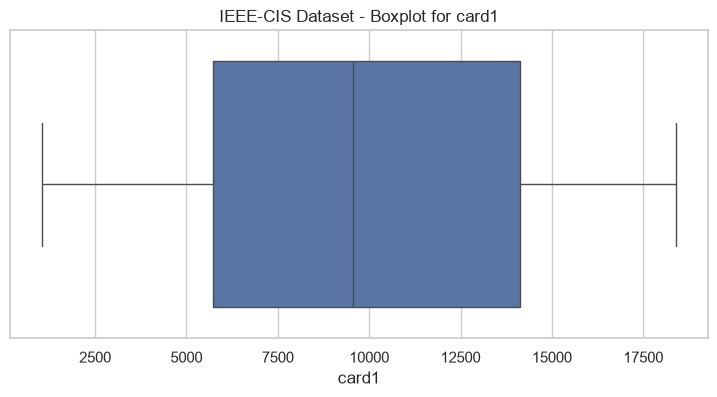

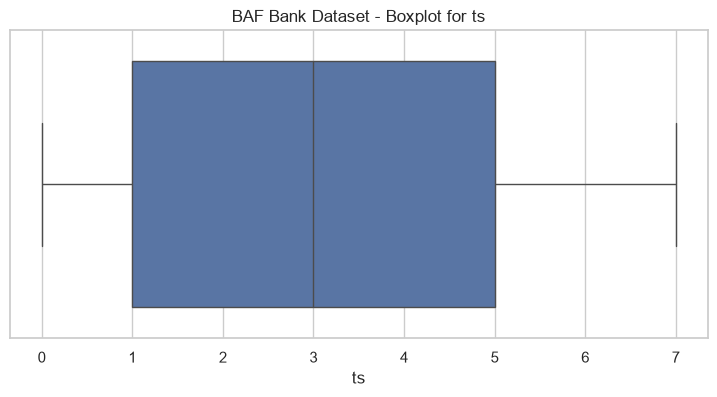

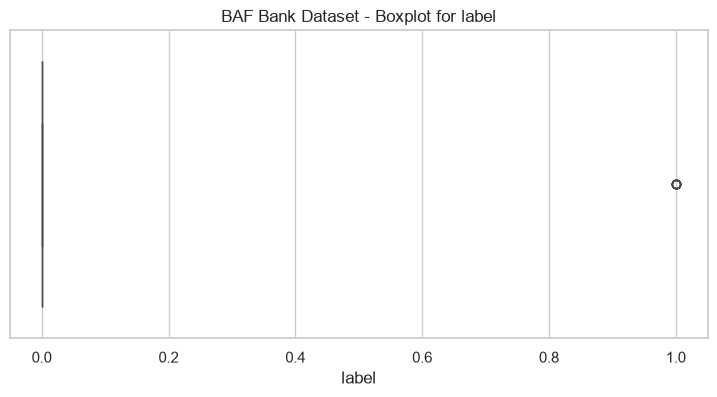

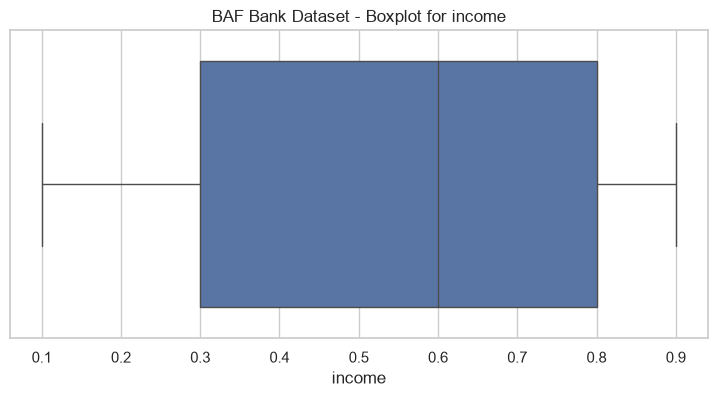

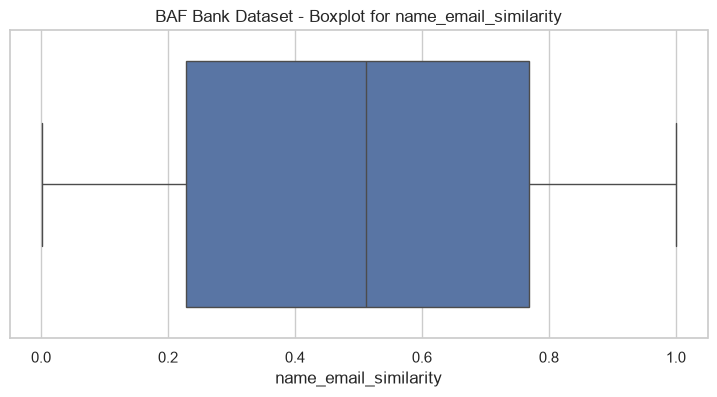

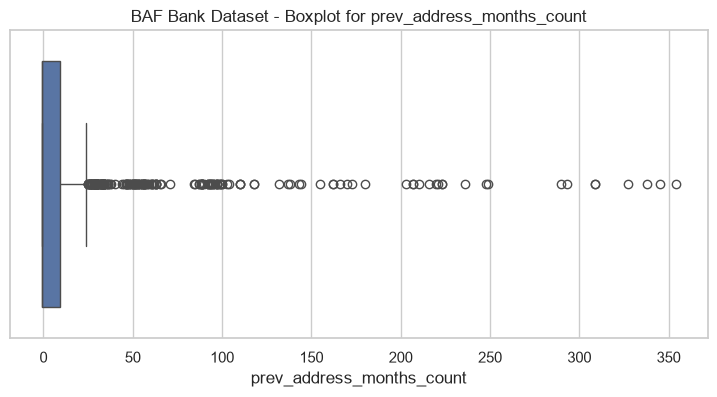

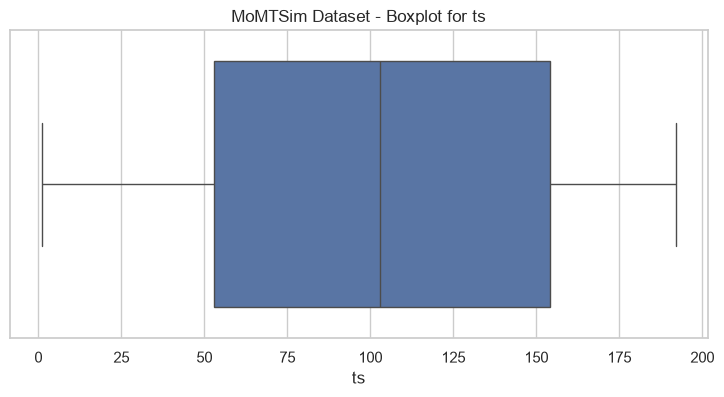

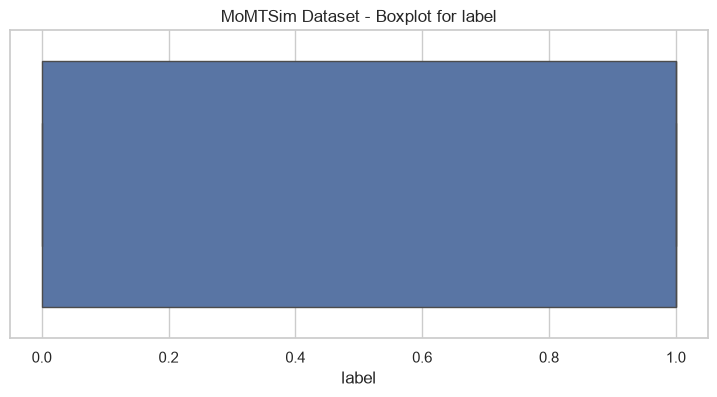

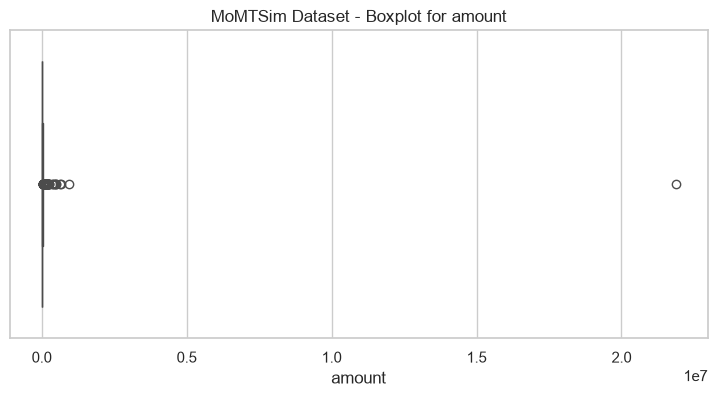

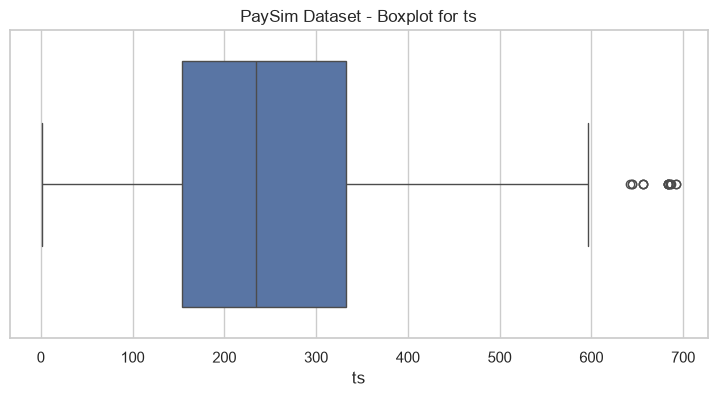

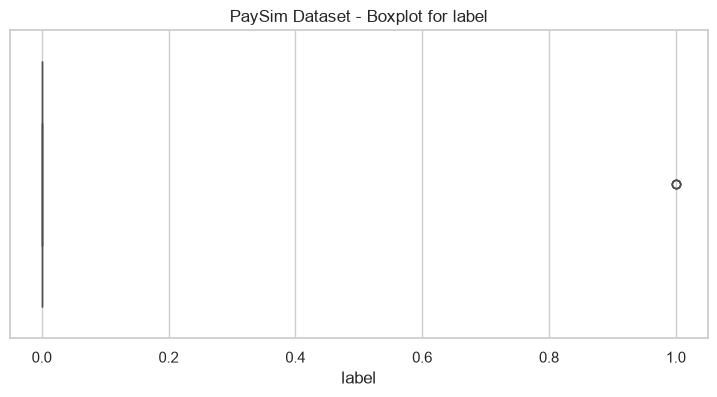

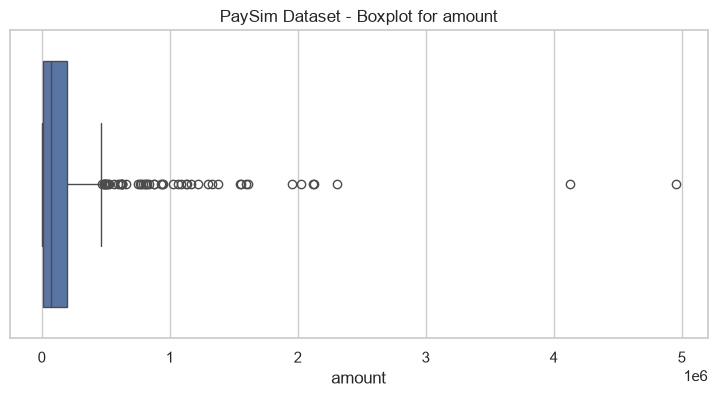

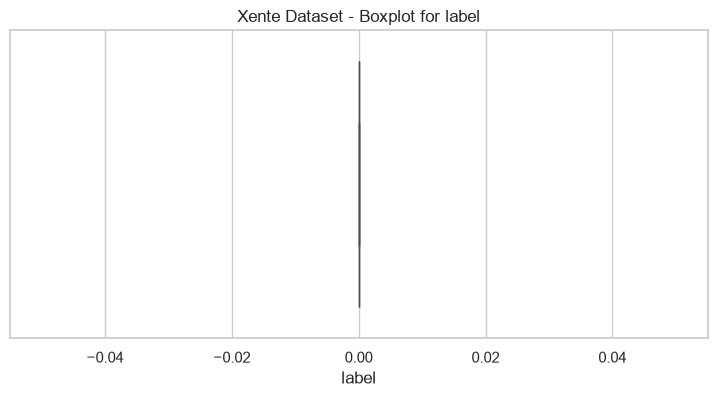

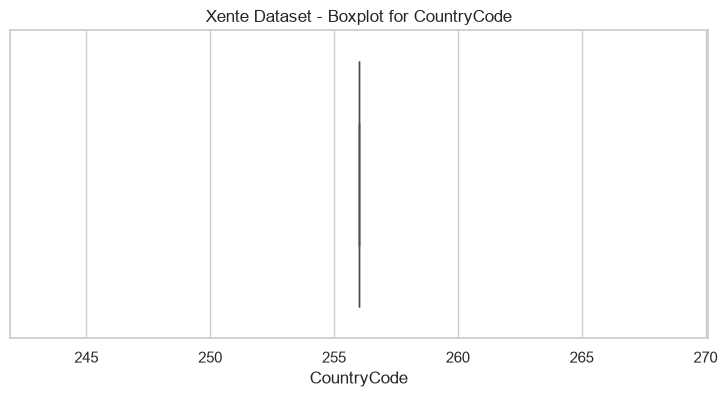

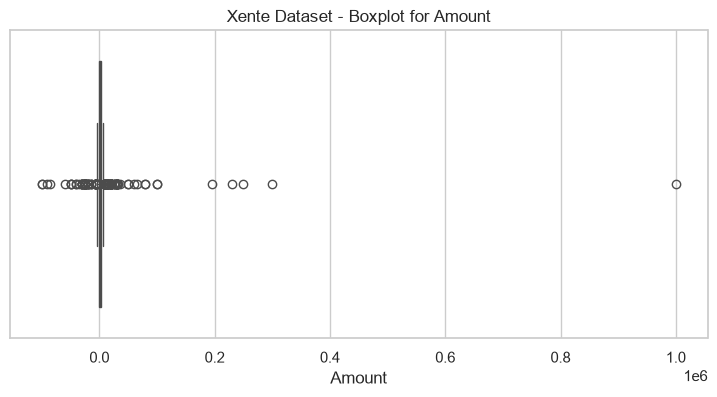

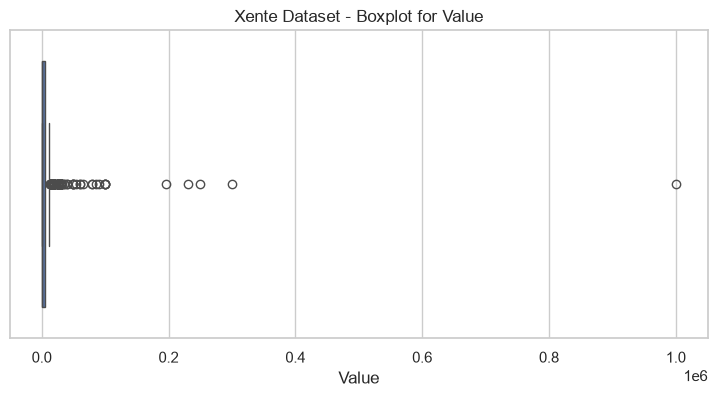

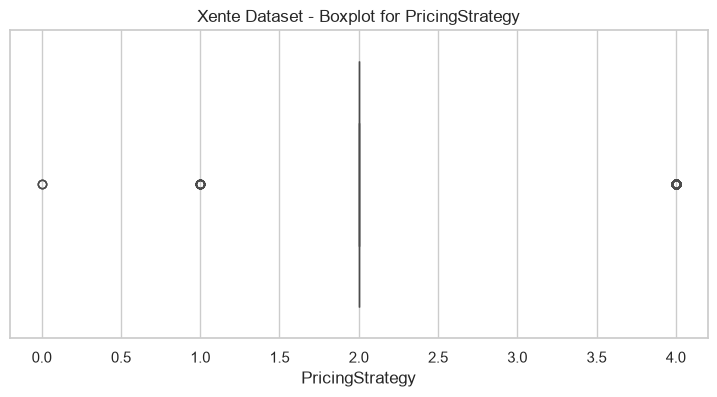

In [19]:
for name, df in datasets.items():
    numerical_columns = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    numerical_columns = numerical_columns[ : 5]

    if not numerical_columns:
        continue
    
    samples = df[numerical_columns].sample(
        min(1000, len(df)),
        random_state = 42
    )

    for col in numerical_columns:
        plt.figure(figsize=(9, 4))
        sns.boxplot(x=samples[col])
        plt.title(f"{name} Dataset - Boxplot for {col}")
        plt.show()

## Final reports

In [20]:
final_report = []

for name, df in datasets.items():

    numerical_columns = df.select_dtypes(
        include=np.number
    ).columns

    categorical_columns = df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns

    final_report.append({
        "Dataset": name,
        "Records": len(df),
        "Features": len(df.columns),
        "Numerical Features": len(numerical_columns),
        "Categorical Features": len(categorical_columns),
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Records": df.duplicated().sum()
    })

final_report_df = pd.DataFrame(final_report)

display(final_report_df)

,Dataset,Records,Features,Numerical Features,Categorical Features,Missing Values,Duplicate Records
0,IEEE-CIS,590540,438,403,34,116704153,0
1,BAF Bank,1000000,36,27,8,2000000,0
2,MoMTSim,4225958,9,3,5,0,78
3,PaySim,6362620,9,3,5,0,0
4,Xente,95662,19,5,12,0,0


## Data quality and leakage analysis

### Validate target columns

In [21]:
for name, df in datasets.items():
    target = target_columns[name]

    print(f"\n", "=" * 60)
    print(f"DATASET: {name}")
    print("=" * 60)

    if target not in df.columns:
        print(f"Target column '{target}' not found in {name} dataset.")
        continue

    print(f"Target: {target}")
    print(f"DataType: {df[target].dtype}")
    print(f"Missing Target: {df[target].isna().sum()}")

    print("\nTarget Distribution:")
    print(df[target].value_counts(dropna=False))

    print("\nTarget Distribution (Percentage):")
    print(df[target].value_counts(normalize=True, dropna=False).mul(100).round(3))


DATASET: IEEE-CIS
Target: label
DataType: int8
Missing Target: 0

Target Distribution:
label
0    569877
1     20663
Name: count, dtype: int64

Target Distribution (Percentage):
label
0    96.501
1     3.499
Name: proportion, dtype: float64

DATASET: BAF Bank
Target: label
DataType: int8
Missing Target: 0

Target Distribution:
label
0    988971
1     11029
Name: count, dtype: int64

Target Distribution (Percentage):
label
0    98.897
1     1.103
Name: proportion, dtype: float64

DATASET: MoMTSim
Target: label
DataType: int8
Missing Target: 0

Target Distribution:
label
1    2233118
0    1992840
Name: count, dtype: int64

Target Distribution (Percentage):
label
1    52.843
0    47.157
Name: proportion, dtype: float64

DATASET: PaySim
Target: label
DataType: int8
Missing Target: 0

Target Distribution:
label
0    6354407
1       8213
Name: count, dtype: int64

Target Distribution (Percentage):
label
0    99.871
1     0.129
Name: proportion, dtype: float64

DATASET: Xente
Target: label
D

### Investigate suspicious columns

In [22]:
suspicious_keywords = [
    "fraud",
    "label",
    "target",
    "class",
    "split",
    "future",
    "outcome",
    "decision",
    "review",
    "investigation"
]

leakage_candidates = []
for name, df in datasets.items():
    target = target_columns[name]

    for col in df.columns:
        if col == target:
            continue

        reason = []

        if any(word in col.lower() for word in suspicious_keywords):
            reason.append("Suspicious column name")

        if df[col].nunique(dropna=False) <=1:
            reason.append("Constant feature")

        if df[col].dtype == df[target].dtype and df[col].equals(df[target]):
            reason.append("Exact match with target")

        if reason:
            leakage_candidates.append({
                "Dataset": name,
                "Feature": col,
                "Reason": ", ".join(reason)
            })


leakage_df = pd.DataFrame(leakage_candidates)
display(leakage_df)

,Dataset,Feature,Reason
0,IEEE-CIS,dataset,Constant feature
1,IEEE-CIS,split,Suspicious column name
2,IEEE-CIS,user_id,Constant feature
3,IEEE-CIS,seen_user,Constant feature
4,BAF Bank,dataset,Constant feature
5,BAF Bank,split,Suspicious column name
6,BAF Bank,user_id,Constant feature
7,BAF Bank,seen_user,Constant feature
8,BAF Bank,device_fraud_count,"Suspicious column name, Constant feature"
9,MoMTSim,dataset,Constant feature


### Check identifier and timestamp columns

In [23]:
identifier_keywords = [
    "id",
    "user",
    "account",
    "customer",
    "transaction",
    "recipient",
    "destination",
]

identifier_report = []
for name, df in datasets.items():
    for col in df.columns:
        if any(word in col.lower() for word in identifier_keywords):
            identifier_report.append({
                "Dataset": name,
                "Feature": col,
                "Unique Values" : df[col].nunique(dropna=False),
                "Unique Percentage" : round(df[col].nunique(dropna=False) / len(df) * 100, 2),
                "Data Type" : str(df[col].dtype)
            })

identifier_df = pd.DataFrame(identifier_report)
display(identifier_df)

,Dataset,Feature,Unique Values,Unique Percentage,Data Type
0,IEEE-CIS,user_id,1,0.00,string
1,IEEE-CIS,seen_user,1,0.00,boolean
2,IEEE-CIS,TransactionID,590540,100.00,int64
3,IEEE-CIS,TransactionAmt,20902,3.54,float64
4,IEEE-CIS,id_01,78,0.01,float64
...,...,...,...,...,...
56,Xente,AccountId,3633,3.80,str
57,Xente,SubscriptionId,3627,3.79,str
58,Xente,ProviderId,6,0.01,str
59,Xente,ProductId,23,0.02,str


In [24]:
for name, df in datasets.items():

    print("\n" + "=" * 65)
    print(f"DATASET: {name}")
    print("=" * 65)

    datetime_columns = df.select_dtypes(
        include=["datetime", "datetimetz"]
    ).columns.tolist()

    possible_time_columns = [
        col for col in df.columns
        if any(
            keyword in col.lower()
            for keyword in ["time", "date", "timestamp", "datetime"]
        )
    ]

    print("Datetime columns:", datetime_columns)
    print("Possible time columns:", possible_time_columns)

    for col in possible_time_columns:
        print(f"\n{col}")
        print("Minimum:", df[col].min())
        print("Maximum:", df[col].max())


DATASET: IEEE-CIS
Datetime columns: []
Possible time columns: []

DATASET: BAF Bank
Datetime columns: []
Possible time columns: ['date_of_birth_distinct_emails_4w']

date_of_birth_distinct_emails_4w
Minimum: 0
Maximum: 39

DATASET: MoMTSim
Datetime columns: []
Possible time columns: []

DATASET: PaySim
Datetime columns: []
Possible time columns: []

DATASET: Xente
Datetime columns: ['ts']
Possible time columns: []


## Investigate predefined train/test splits


In [25]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    if "split" in df.columns:
        print("\nSplit Distribution:")
        display(df["split"].value_counts(dropna=False))

        print("\nSplit Distribution (Percentage):")
        display(pd.crosstab(df["split"], df[target_columns[name]], normalize="index").mul(100).round(2))


    else:
        print("\nNo 'predefined split' column found in this dataset.")


IEEE-CIS

Split Distribution:


split
train         413378
validation     88581
test           88581
Name: count, dtype: int64


Split Distribution (Percentage):


label,0,1
split,,
train,96.48,3.52
validation,96.57,3.43
test,96.52,3.48



BAF Bank

Split Distribution:


split
train         794989
validation    108168
test           96843
Name: count, dtype: int64

... (10 outputs left out)


Xente

Split Distribution:


split
train         66963
test          14350
validation    14349
Name: count, dtype: int64


Split Distribution (Percentage):


label,0,1
split,,
train,99.84,0.16
validation,99.73,0.27
test,99.65,0.35


### Print the actual split values

In [26]:
for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(f"DATASET: {name}")
    print("=" * 60)

    if "split" in df.columns:
        print("\nSplit Distribution: ")
        print(df["split"].value_counts(dropna=False).to_string())

        print("\nSplit Distribution (Percentage): ")
        fraud_rate = (
            df.groupby("split", dropna=False)[target_columns[name]]
            .mean()
            .mul(100)
            .round(3)
        )

        print(fraud_rate.to_string())

    else:
        print("\nNo 'split' column found in this dataset.")


DATASET: IEEE-CIS

Split Distribution: 
split
train         413378
validation     88581
test           88581

Split Distribution (Percentage): 
split
train         3.517
validation    3.434
test          3.480

DATASET: BAF Bank

Split Distribution: 
split
train         794989
validation    108168
test           96843

Split Distribution (Percentage): 
split
train         1.025
validation    1.341
test          1.475

DATASET: MoMTSim

Split Distribution: 
split
train         2978508
test           628554
validation     618896

Split Distribution (Percentage): 
split
train         53.765
validation    51.006
test          50.281

DATASET: PaySim

Split Distribution: 
split
train         4463587
validation     980416
test           918617

Split Distribution (Percentage): 
split
train         0.082
validation    0.058
test          0.436

DATASET: Xente

Split Distribution: 
split
train         66963
test          14350
validation    14349

Split Distribution (Percentage): 
split
train

### Check whether split categories contain missing values

In [27]:
for name, df in datasets.items():

    if "split" in df.columns:

        print(
            f"{name}: "
            f"{df['split'].isna().sum()} missing split values"
        )

IEEE-CIS: 0 missing split values
BAF Bank: 0 missing split values
MoMTSim: 0 missing split values
PaySim: 0 missing split values
Xente: 0 missing split values


### Constant Feature Analysis

In [28]:
constant_features = []

for name, df in datasets.items():
    for col in df.columns:
        if col in [target_columns[name], "split"]:
            continue

        unique_count = df[col].nunique(dropna=False)
        if unique_count <= 1:
            constant_features.append({
                "Dataset" : name,
                "Feature" : col,
                "Unique Values" : unique_count,
                "Missing Values" : df[col].isna().sum(),
                "Example Values" : df[col].iloc[0]
            })

constant_features_df = pd.DataFrame(constant_features)
display(constant_features_df)

,Dataset,Feature,Unique Values,Missing Values,Example Values
0,IEEE-CIS,dataset,1,0,ieee
1,IEEE-CIS,user_id,1,590540,<NA>
2,IEEE-CIS,seen_user,1,590540,<NA>
3,BAF Bank,dataset,1,0,baf
4,BAF Bank,user_id,1,1000000,<NA>
5,BAF Bank,seen_user,1,1000000,<NA>
6,BAF Bank,device_fraud_count,1,0,0
7,MoMTSim,dataset,1,0,momtsim
8,PaySim,dataset,1,0,paysim
9,Xente,dataset,1,0,xente
